# 02 — Exploratory Data Analysis

**Input:** `data/processed/*.parquet` produced by the PySpark notebook 01 (no re-cleaning happens here).
**Output:** figures in `reports/figures/` and the computed findings printed at the end.

Every analysis states the **question**, the **columns** used and the **chart** chosen. All numbers in the
findings are computed from the data in this notebook.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = PROJECT_ROOT / "data" / "processed"
FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA / "movies_processed.parquet")
genre_stats = pd.read_parquet(DATA / "genre_stats.parquet")
yearly = pd.read_parquet(DATA / "yearly_stats.parquet")
ratings = pd.read_parquet(DATA / "movie_ratings_summary.parquet")
meta = json.loads((DATA / "processing_metadata.json").read_text())
findings = {}

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()

print(df.shape)
df[["popularity", "budget", "runtime", "release_year", "num_genres", "revenue", "vote_count"]].describe().round(2)

(44861, 46)


,popularity,budget,runtime,release_year,num_genres,revenue,vote_count
count,44861.00,8.609000e+03,44861.00,44861.00,44861.00,7.385000e+03,44861.00
mean,2.95,2.228612e+07,96.87,1991.83,2.01,6.896865e+07,111.23
std,6.03,3.464786e+07,28.47,24.08,1.13,1.466090e+08,494.43
min,0.00,1.000000e+03,1.00,1874.00,0.00,1.000000e+00,0.00
25%,0.40,2.200000e+06,87.00,1978.00,1.00,2.405420e+06,3.00
50%,1.14,9.000000e+06,95.00,2001.00,2.00,1.687267e+07,10.00
75%,3.74,2.600000e+07,107.00,2010.00,3.00,6.764269e+07,35.00
max,547.49,3.800000e+08,400.00,2017.00,8.00,2.787965e+09,14075.00


## 1. Popularity distribution
**Question:** How is the target distributed? · **Columns:** `popularity`, `log_popularity` · **Chart:** histograms

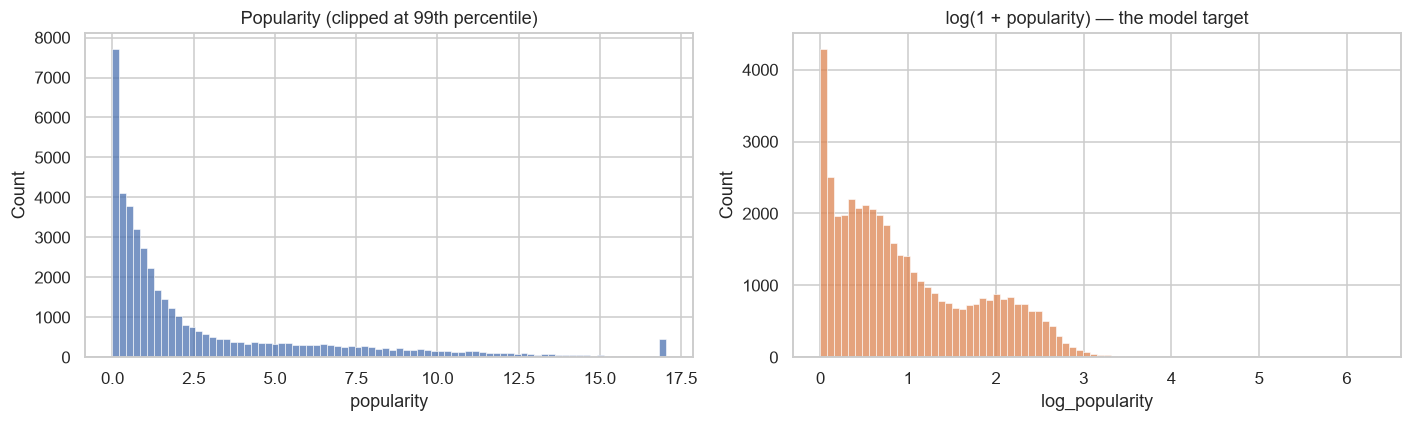

Median popularity 1.14, 90th pct 8.36, 99th pct 17.03, max 547.5; skewness 29.2 (log scale: 0.79).


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["popularity"].clip(upper=df["popularity"].quantile(0.99)), bins=80, ax=axes[0])
axes[0].set_title("Popularity (clipped at 99th percentile)")
sns.histplot(df["log_popularity"], bins=80, ax=axes[1], color="#dd8452")
axes[1].set_title("log(1 + popularity) — the model target")
save("popularity_distribution")

q = df["popularity"].quantile([0.5, 0.9, 0.99])
findings["popularity"] = (f"Median popularity {q[0.5]:.2f}, 90th pct {q[0.9]:.2f}, 99th pct {q[0.99]:.2f}, "
                          f"max {df['popularity'].max():.1f}; skewness {df['popularity'].skew():.1f} "
                          f"(log scale: {df['log_popularity'].skew():.2f}).")
print(findings["popularity"])

## 2. Popularity by genre
**Question:** Which genres are associated with higher popularity? · **Columns:** `genre_stats` (Spark aggregation),
`genre_*`, `popularity` · **Chart:** bar chart of median popularity + box plot

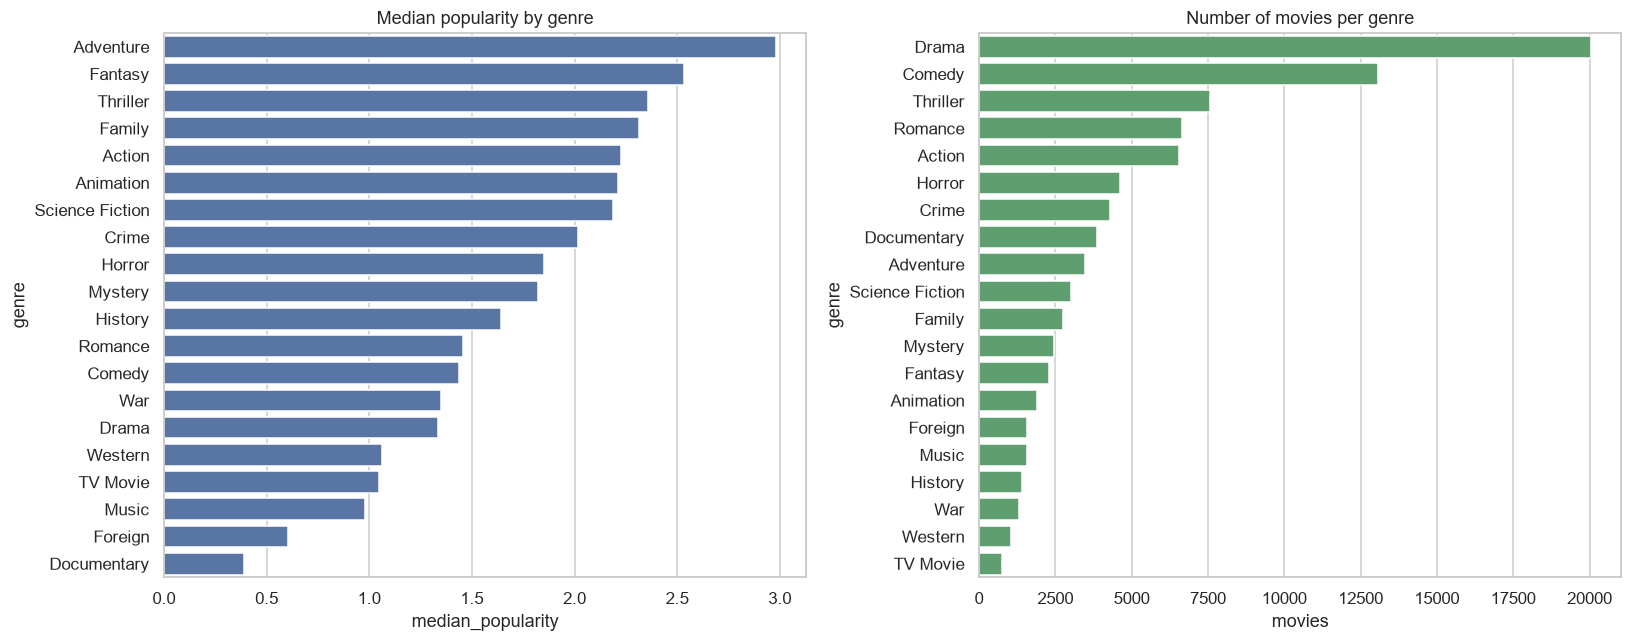

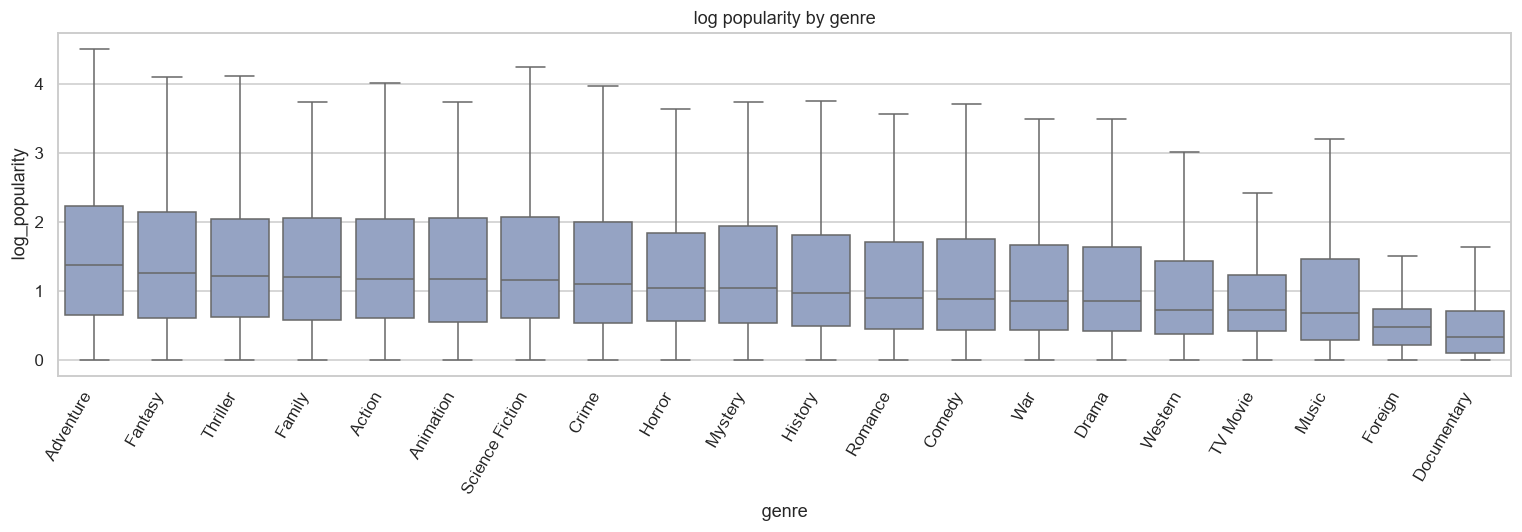

Highest median popularity: Adventure (2.98); lowest: Documentary (0.39). Most common genre: Drama (20043 movies).


In [3]:
gs = genre_stats.sort_values("median_popularity", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=gs, y="genre", x="median_popularity", ax=axes[0], color="#4c72b0")
axes[0].set_title("Median popularity by genre")
sns.barplot(data=gs.sort_values("movies", ascending=False), y="genre", x="movies", ax=axes[1], color="#55a868")
axes[1].set_title("Number of movies per genre")
save("genre_popularity")

long = pd.concat([pd.DataFrame({"genre": g, "log_popularity": df.loc[df[c] == 1, "log_popularity"]})
                  for g, c in zip(meta["genres"], meta["genre_columns"])])
order = long.groupby("genre")["log_popularity"].median().sort_values(ascending=False).index
plt.figure(figsize=(14, 5))
sns.boxplot(data=long, x="genre", y="log_popularity", order=order, showfliers=False, color="#8da0cb")
plt.xticks(rotation=60, ha="right"); plt.title("log popularity by genre")
save("genre_boxplot")

top, bottom = gs.iloc[0], gs.iloc[-1]
findings["genre"] = (f"Highest median popularity: {top.genre} ({top.median_popularity:.2f}); lowest: "
                     f"{bottom.genre} ({bottom.median_popularity:.2f}). Most common genre: "
                     f"{gs.sort_values('movies').iloc[-1].genre} ({int(gs.movies.max())} movies).")
print(findings["genre"])

## 3. Movie releases by year
**Question:** How has the number of releases and their popularity changed over time? ·
**Columns:** `yearly_stats` (Spark aggregation) · **Chart:** line charts

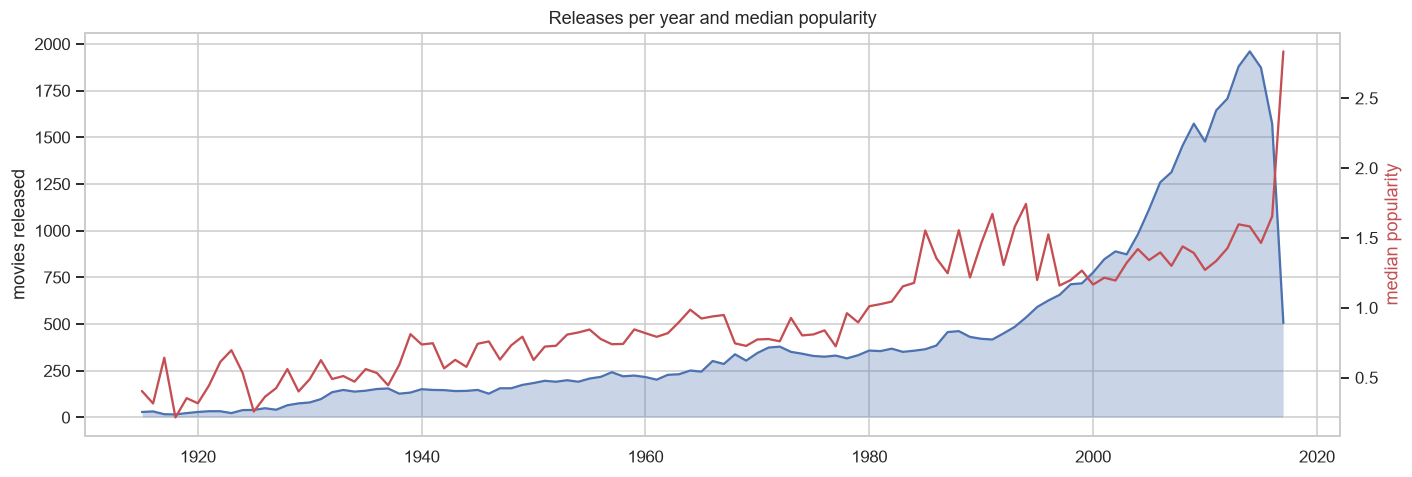

Peak release year in the data: 2014 (1960 movies). 53% of the movies were released in 2000 or later. Note: 2017 is incomplete (data collected in 2017).


In [4]:
y = yearly[(yearly.release_year >= 1915) & (yearly.release_year <= 2017)]
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.fill_between(y.release_year, y.movies, alpha=0.3); ax1.plot(y.release_year, y.movies, lw=1.5)
ax1.set_ylabel("movies released")
ax2 = ax1.twinx(); ax2.plot(y.release_year, y.median_popularity, color="#c44e52", lw=1.5)
ax2.set_ylabel("median popularity", color="#c44e52"); ax2.grid(False)
plt.title("Releases per year and median popularity")
save("releases_by_year")

peak = yearly.loc[yearly.movies.idxmax()]
share_2000 = (df.release_year >= 2000).mean() * 100
findings["year"] = (f"Peak release year in the data: {int(peak.release_year)} ({int(peak.movies)} movies). "
                    f"{share_2000:.0f}% of the movies were released in 2000 or later. "
                    f"Note: 2017 is incomplete (data collected in 2017).")
print(findings["year"])

## 4. Budget vs popularity
**Question:** Do bigger budgets go with higher popularity? · **Columns:** `budget`, `budget_known`, `popularity` ·
**Chart:** scatter (log-log) + box plot by budget tier

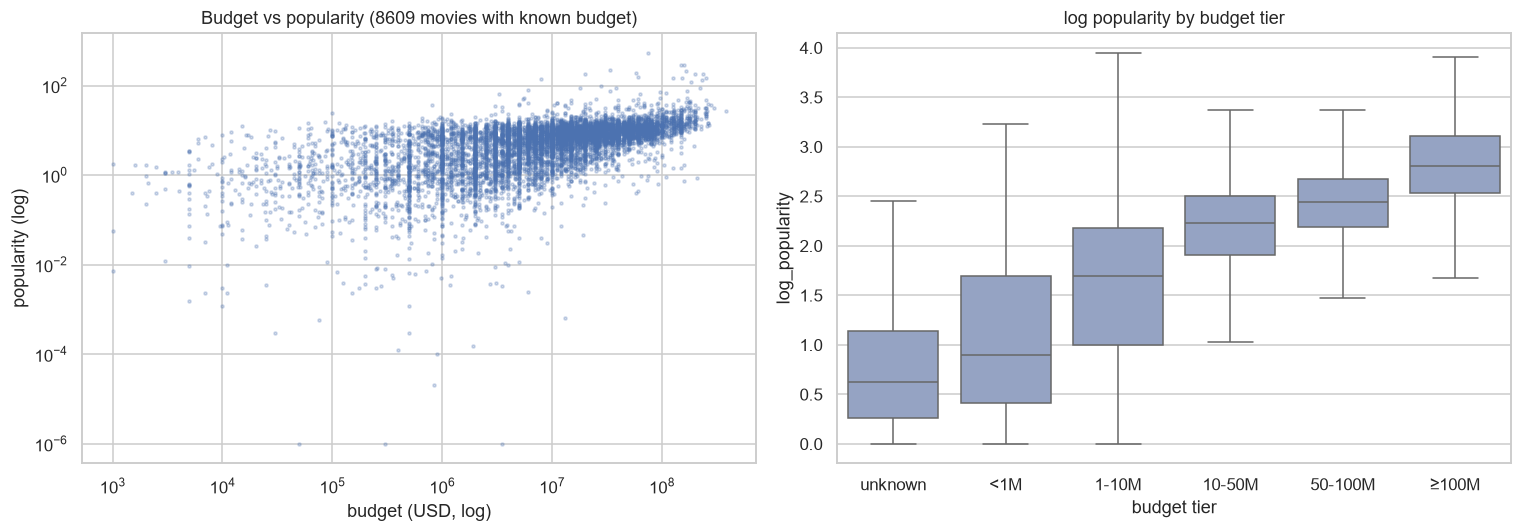

Only 19% of movies report a budget. Among them, Spearman correlation budget↔popularity = 0.60. Median popularity with known budget 6.50 vs unknown budget 0.87.


In [5]:
kb = df[df.budget_known == 1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(kb.budget, kb.popularity, s=4, alpha=0.25)
axes[0].set(xscale="log", yscale="log", xlabel="budget (USD, log)", ylabel="popularity (log)",
            title=f"Budget vs popularity ({len(kb)} movies with known budget)")

bins = [0, 1e6, 1e7, 5e7, 1e8, 1e10]
labels = ["<1M", "1-10M", "10-50M", "50-100M", "≥100M"]
tier = pd.cut(df.budget, bins=bins, labels=labels).cat.add_categories("unknown").fillna("unknown")
sns.boxplot(x=tier, y=df.log_popularity, order=["unknown"] + labels, showfliers=False, ax=axes[1], color="#8da0cb")
axes[1].set(title="log popularity by budget tier", xlabel="budget tier")
save("budget_vs_popularity")

rho = kb[["budget", "popularity"]].corr(method="spearman").iloc[0, 1]
med_known = df.loc[df.budget_known == 1, "popularity"].median()
med_unknown = df.loc[df.budget_known == 0, "popularity"].median()
findings["budget"] = (f"Only {df.budget_known.mean()*100:.0f}% of movies report a budget. Among them, Spearman "
                      f"correlation budget↔popularity = {rho:.2f}. Median popularity with known budget "
                      f"{med_known:.2f} vs unknown budget {med_unknown:.2f}.")
print(findings["budget"])

## 5. Runtime vs popularity
**Question:** Is runtime related to popularity? · **Columns:** `runtime`, `log_popularity` · **Chart:** hexbin + binned medians

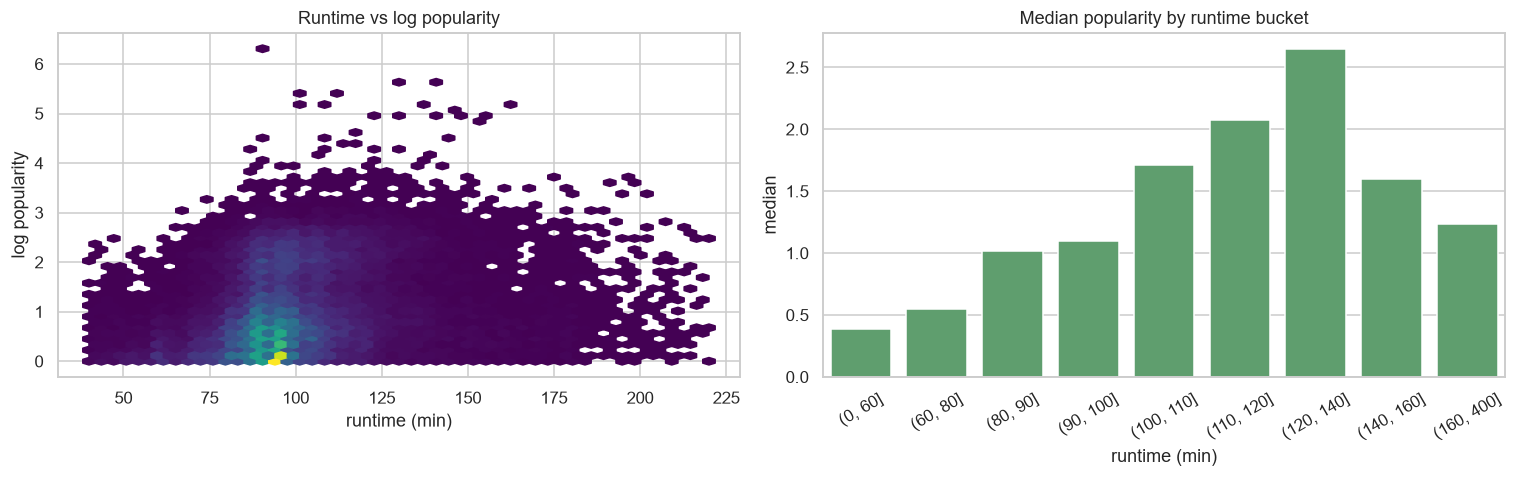

Median runtime 95 min. Spearman runtime↔popularity = 0.27; highest median popularity in the (120, 140] min bucket.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sub = df[df.runtime.between(40, 220)]
axes[0].hexbin(sub.runtime, sub.log_popularity, gridsize=50, cmap="viridis", mincnt=1)
axes[0].set(xlabel="runtime (min)", ylabel="log popularity", title="Runtime vs log popularity")
rt_bins = pd.cut(df.runtime, [0, 60, 80, 90, 100, 110, 120, 140, 160, 400])
rt = df.groupby(rt_bins, observed=True)["popularity"].agg(["median", "count"]).reset_index()
rt["runtime"] = rt["runtime"].astype(str)
sns.barplot(data=rt, x="runtime", y="median", ax=axes[1], color="#55a868")
axes[1].set(title="Median popularity by runtime bucket", xlabel="runtime (min)"); axes[1].tick_params(axis="x", rotation=30)
save("runtime_vs_popularity")

rho_rt = df[["runtime", "popularity"]].corr(method="spearman").iloc[0, 1]
best_bucket = rt.loc[rt["median"].idxmax(), "runtime"]
findings["runtime"] = (f"Median runtime {df.runtime.median():.0f} min. Spearman runtime↔popularity = {rho_rt:.2f}; "
                       f"highest median popularity in the {best_bucket} min bucket.")
print(findings["runtime"])

## 6. Popularity by release month
**Question:** Does release timing matter? · **Columns:** `release_month`, `popularity` · **Chart:** bar chart

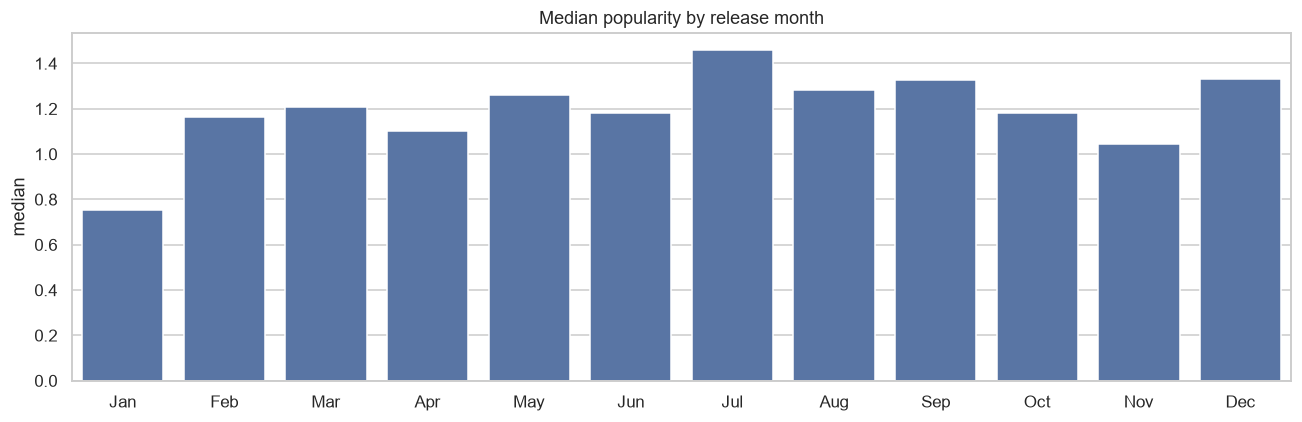

Highest median popularity for Jul releases (1.46), lowest for Jan (0.75). Most releases: Jan — note January 1st is often a placeholder date in TMDB.


In [7]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
m = df.groupby("release_month")["popularity"].agg(["median", "count"]).reset_index()
fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(data=m, x="release_month", y="median", ax=ax, color="#4c72b0")
ax.set_xticks(range(12)); ax.set_xticklabels(month_names); ax.set(title="Median popularity by release month", xlabel="")
save("popularity_by_month")
mx, mn = m.loc[m["median"].idxmax()], m.loc[m["median"].idxmin()]
findings["month"] = (f"Highest median popularity for {month_names[int(mx.release_month)-1]} releases ({mx['median']:.2f}), "
                     f"lowest for {month_names[int(mn.release_month)-1]} ({mn['median']:.2f}). Most releases: "
                     f"{month_names[int(m.loc[m['count'].idxmax(), 'release_month'])-1]} — note January 1st is often a "
                     f"placeholder date in TMDB.")
print(findings["month"])

## 7. Popularity by original language
**Question:** How does popularity vary across production languages? · **Columns:** `original_language`, `popularity` ·
**Chart:** horizontal bar chart (languages with ≥ 200 movies)

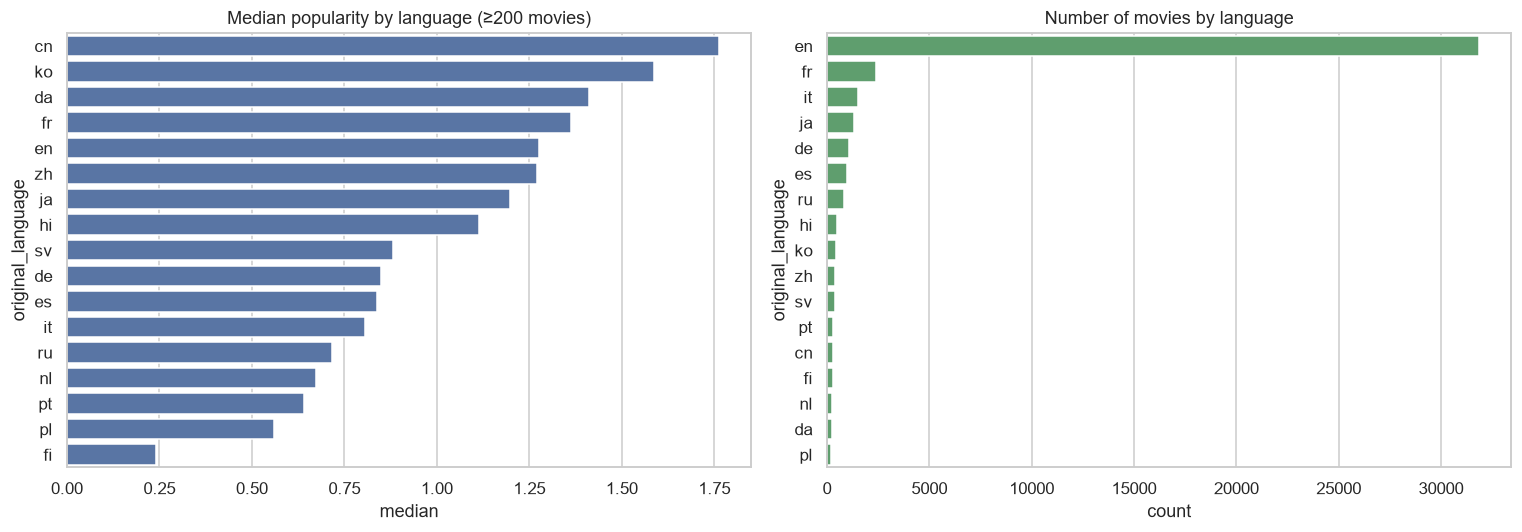

English accounts for 71% of movies. Highest median popularity among languages with ≥200 movies: 'cn' (1.76); lowest: 'fi' (0.24).


In [8]:
lang = (df.groupby("original_language")["popularity"].agg(["median", "count"])
          .query("count >= 200").sort_values("median", ascending=False).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=lang, y="original_language", x="median", ax=axes[0], color="#4c72b0")
axes[0].set_title("Median popularity by language (≥200 movies)")
sns.barplot(data=lang.sort_values("count", ascending=False), y="original_language", x="count", ax=axes[1], color="#55a868")
axes[1].set_title("Number of movies by language")
save("popularity_by_language")
en_share = (df.original_language == "en").mean() * 100
findings["language"] = (f"English accounts for {en_share:.0f}% of movies. Highest median popularity among languages "
                        f"with ≥200 movies: '{lang.iloc[0].original_language}' ({lang.iloc[0]['median']:.2f}); lowest: "
                        f"'{lang.iloc[-1].original_language}' ({lang.iloc[-1]['median']:.2f}).")
print(findings["language"])

## 8. Correlation analysis
**Question:** Which numeric variables move together with popularity? · **Columns:** model features plus post-release
variables (shown for context only) · **Chart:** Spearman correlation heatmap (robust to skew)

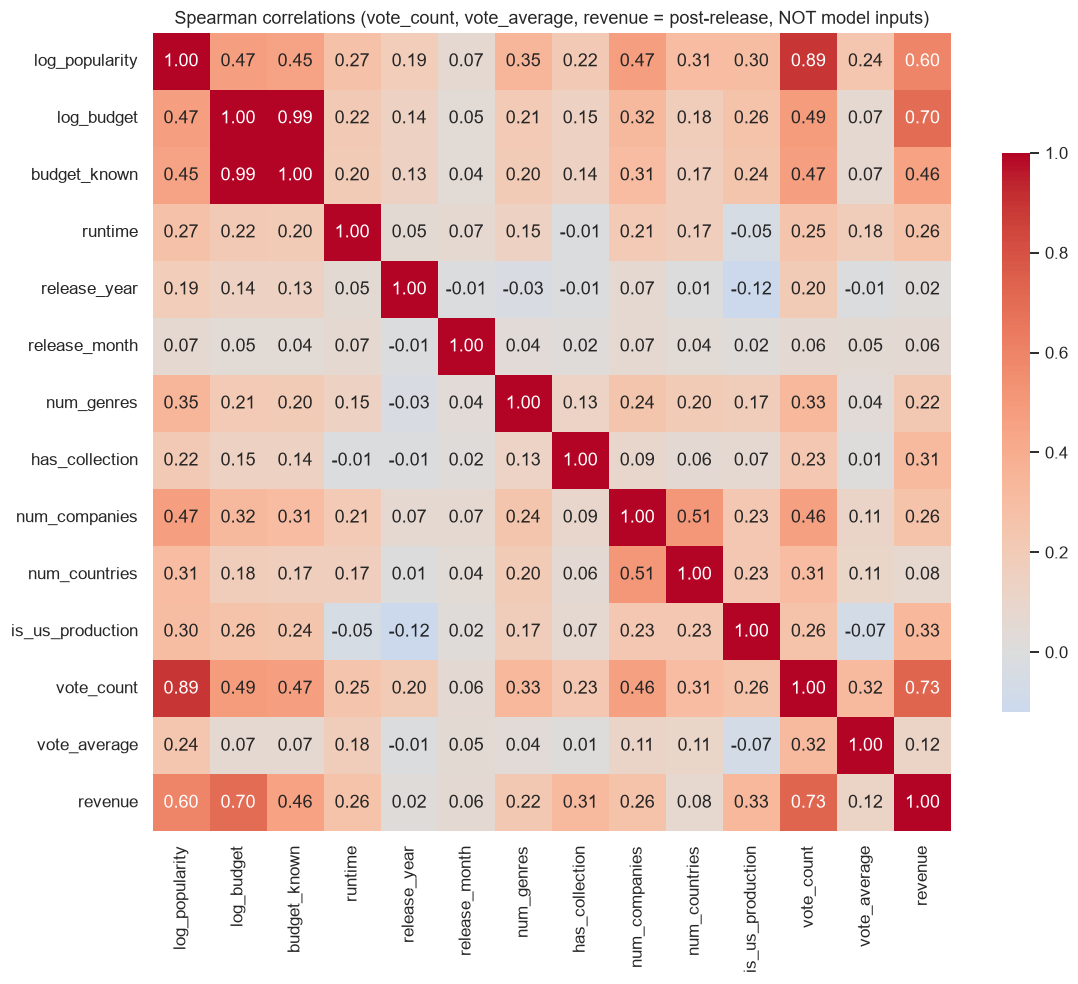

vote_count          0.894
revenue             0.601
num_companies       0.470
log_budget          0.468
budget_known        0.447
num_genres          0.345
num_countries       0.309
is_us_production    0.302
runtime             0.271
vote_average        0.240
has_collection      0.216
release_year        0.186
release_month       0.071
Name: log_popularity, dtype: float64
Strongest pre-release correlates of popularity: num_companies (0.47), log_budget (0.47), budget_known (0.45). Post-release vote_count correlates at 0.89 — confirming popularity largely reflects audience activity after release.


In [9]:
cols = ["log_popularity", "log_budget", "budget_known", "runtime", "release_year", "release_month", "num_genres",
        "has_collection", "num_companies", "num_countries", "is_us_production", "vote_count", "vote_average", "revenue"]
corr = df[cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Spearman correlations (vote_count, vote_average, revenue = post-release, NOT model inputs)")
save("correlation_heatmap")
c = corr["log_popularity"].drop("log_popularity").sort_values(ascending=False)
print(c.round(3))
pre = c.drop(["vote_count", "vote_average", "revenue"])
findings["correlation"] = (f"Strongest pre-release correlates of popularity: " +
                           ", ".join(f"{k} ({v:.2f})" for k, v in pre.head(3).items()) +
                           f". Post-release vote_count correlates at {c['vote_count']:.2f} — confirming popularity "
                           f"largely reflects audience activity after release.")
print(findings["correlation"])

## 9. Distribution of movie budgets
**Question:** What does the budget distribution look like? · **Columns:** `budget` · **Chart:** histogram (log scale)

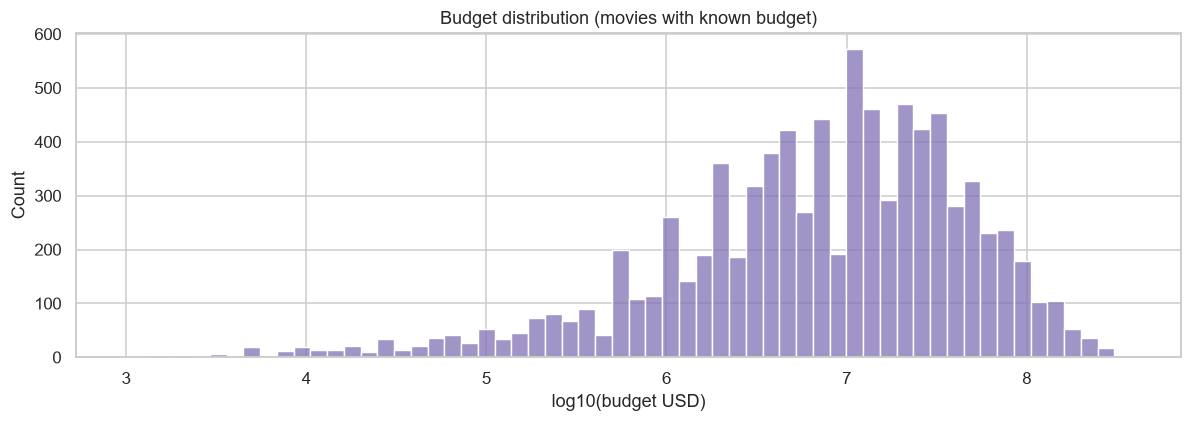

Median known budget $9.0M, mean $22.3M, max $380M — strongly right-skewed, hence the log transform.


In [10]:
plt.figure(figsize=(11, 4))
sns.histplot(np.log10(kb.budget), bins=60, color="#8172b3")
plt.xlabel("log10(budget USD)"); plt.title("Budget distribution (movies with known budget)")
save("budget_distribution")
findings["budget_dist"] = (f"Median known budget ${kb.budget.median()/1e6:.1f}M, mean ${kb.budget.mean()/1e6:.1f}M, "
                           f"max ${kb.budget.max()/1e6:.0f}M — strongly right-skewed, hence the log transform.")
print(findings["budget_dist"])

## 10. Additional analyses — franchises and audience engagement
**Questions:** Do movies belonging to a collection (franchise) score higher? How strongly does audience activity
(MovieLens ratings, joined in Spark) track TMDB popularity? · **Charts:** box plot, scatter

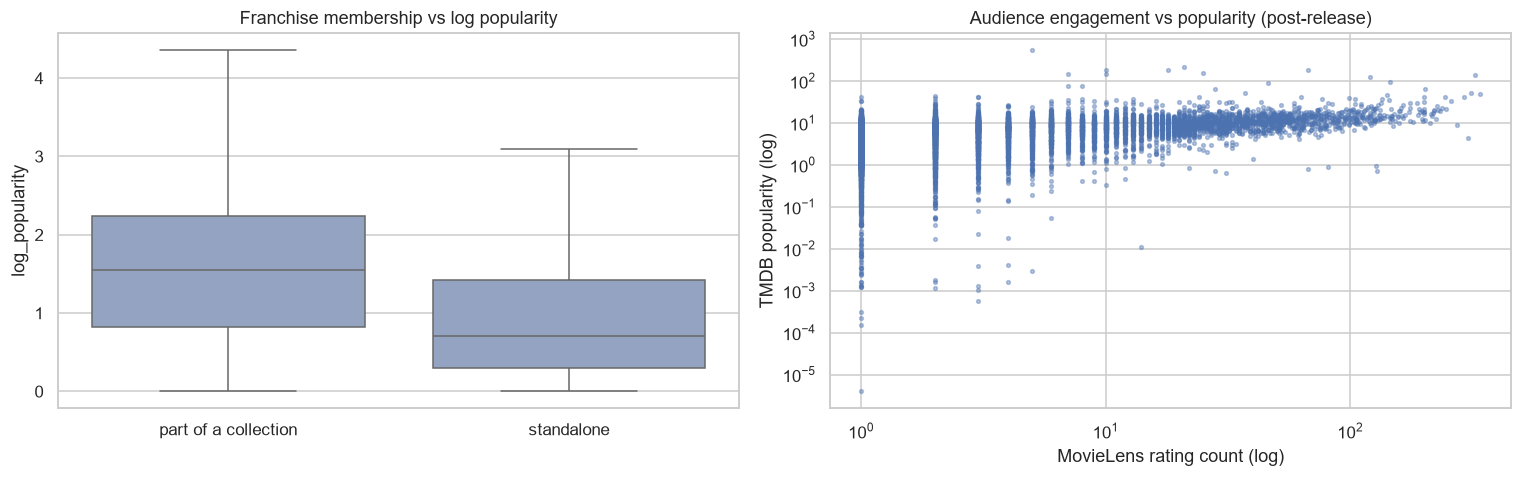

Collection/franchise movies: median popularity 3.71 vs 1.03 for standalone films (10% of movies belong to a collection).
Across 9004 movies joined with MovieLens ratings, Spearman(rating count, popularity) = 0.51 — post-release engagement is strongly linked to popularity, which is why it must not be a pre-release model input.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=df.has_collection.map({0: "standalone", 1: "part of a collection"}), y=df.log_popularity,
            showfliers=False, ax=axes[0], color="#8da0cb")
axes[0].set(xlabel="", title="Franchise membership vs log popularity")
axes[1].scatter(ratings.ml_rating_count, ratings.popularity, s=6, alpha=0.4)
axes[1].set(xscale="log", yscale="log", xlabel="MovieLens rating count (log)", ylabel="TMDB popularity (log)",
            title="Audience engagement vs popularity (post-release)")
save("franchise_and_engagement")
med_c = df.groupby("has_collection")["popularity"].median()
rho_ml = ratings[["ml_rating_count", "popularity"]].corr(method="spearman").iloc[0, 1]
findings["franchise"] = (f"Collection/franchise movies: median popularity {med_c[1]:.2f} vs {med_c[0]:.2f} for standalone "
                         f"films ({df.has_collection.mean()*100:.0f}% of movies belong to a collection).")
findings["engagement"] = (f"Across {len(ratings)} movies joined with MovieLens ratings, Spearman(rating count, popularity) "
                          f"= {rho_ml:.2f} — post-release engagement is strongly linked to popularity, which is why it "
                          f"must not be a pre-release model input.")
print(findings["franchise"]); print(findings["engagement"])

## Key findings (computed above)

In [12]:
for k, v in findings.items():
    print(f"• [{k}] {v}\n")
(PROJECT_ROOT / "reports" / "eda_findings.json").write_text(json.dumps(findings, indent=2, ensure_ascii=False), encoding="utf-8")

• [popularity] Median popularity 1.14, 90th pct 8.36, 99th pct 17.03, max 547.5; skewness 29.2 (log scale: 0.79).

• [genre] Highest median popularity: Adventure (2.98); lowest: Documentary (0.39). Most common genre: Drama (20043 movies).

• [year] Peak release year in the data: 2014 (1960 movies). 53% of the movies were released in 2000 or later. Note: 2017 is incomplete (data collected in 2017).

• [budget] Only 19% of movies report a budget. Among them, Spearman correlation budget↔popularity = 0.60. Median popularity with known budget 6.50 vs unknown budget 0.87.

• [runtime] Median runtime 95 min. Spearman runtime↔popularity = 0.27; highest median popularity in the (120, 140] min bucket.

• [month] Highest median popularity for Jul releases (1.46), lowest for Jan (0.75). Most releases: Jan — note January 1st is often a placeholder date in TMDB.

• [language] English accounts for 71% of movies. Highest median popularity among languages with ≥200 movies: 'cn' (1.76); lowest: 'fi' (0.

1761